In [222]:
from google.colab import drive
drive.mount('/content/drive')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.plotting import scatter_matrix

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [223]:
FILE_PATH = '/content/drive/MyDrive/COVID-19 Coronavirus.csv'
try:
    df = pd.read_csv(FILE_PATH)
    print(f"Successfully loaded {FILE_PATH}")
except FileNotFoundError:
    print(f"ERROR: The file {FILE_PATH} was not found. Please check the path.")

Successfully loaded /content/drive/MyDrive/COVID-19 Coronavirus.csv


In [224]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225 entries, 0 to 224
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Country                  225 non-null    object 
 1   Other names              224 non-null    object 
 2   ISO 3166-1 alpha-3 CODE  225 non-null    object 
 3   Population               225 non-null    int64  
 4   Continent                225 non-null    object 
 5   Total Cases              225 non-null    int64  
 6   Total Deaths             225 non-null    int64  
 7   Tot Cases//1M pop        225 non-null    int64  
 8   Tot Deaths/1M pop        225 non-null    int64  
 9   Death percentage         225 non-null    float64
dtypes: float64(1), int64(5), object(4)
memory usage: 17.7+ KB


In [225]:
df.head()

,Country,Other names,ISO 3166-1 alpha-3 CODE,Population,Continent,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
0,Afghanistan,Afghanistan,AFG,40462186,Asia,177827,7671,4395,190,4.313743
1,Albania,Albania,ALB,2872296,Europe,273870,3492,95349,1216,1.275058
2,Algeria,Algeria,DZA,45236699,Africa,265691,6874,5873,152,2.587216
3,Andorra,Andorra,AND,77481,Europe,40024,153,516565,1975,0.382271
4,Angola,Angola,AGO,34654212,Africa,99194,1900,2862,55,1.915438


In [226]:
 print("\n---Data Processing: Column Renaming---")

original_cols = df.columns.tolist()
cleaned_cols_map = {
    'Other names': 'Other_names_original',
    'ISO 3166-1 alpha-3 CODE': 'ISO_Code',
    'Total Cases': 'Total_Cases',
    'Total Deaths': 'Total_Deaths',
    'Tot Cases//1M pop': 'Cases_per_1M_pop',
    'Tot Deaths/1M pop': 'Deaths_per_1M_pop',
    'Death percentage': 'Death_percentage'
}
if 'Country,Other names' in df.columns: # Handle combined Country column from CSV
    df = df.rename(columns={'Country,Other names': 'Country'})

df = df.rename(columns=cleaned_cols_map)
df.columns = df.columns.str.replace('\xa0', ' ').str.replace('//', '_per_').str.replace('/', '_per_').str.replace(' ', '_')

# Re-apply specific renames if generic cleaning altered them
df = df.rename(columns={
    'Tot_Cases_per_1M_pop': 'Cases_per_1M_pop',
    'Tot_Deaths_per_1M_pop': 'Deaths_per_1M_pop'
})
for col in df.columns: # Ensure all / are _per_
    new_col_name = col.replace('/', '_per_')
    df = df.rename(columns={col: new_col_name})

print("\nRenamed columns:")
print(list(df.columns))

numerical_cols_cleaned = ['Population', 'Total_Cases', 'Total_Deaths',
                          'Cases_per_1M_pop', 'Deaths_per_1M_pop', 'Death_percentage']
categorical_cols_cleaned = ['Country', 'ISO_Code', 'Continent']


---Data Processing: Column Renaming---

Renamed columns:
['Country', 'Other_names_original', 'ISO_Code', 'Population', 'Continent', 'Total_Cases', 'Total_Deaths', 'Cases_per_1M_pop', 'Deaths_per_1M_pop', 'Death_percentage']


In [227]:
print("\n---Data Processing: Duplicate Rows Check---")
duplicate_rows = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_rows}")
if duplicate_rows > 0:
    df.drop_duplicates(inplace=True)
    print(f"Dropped duplicate rows. New shape: {df.shape}")


---Data Processing: Duplicate Rows Check---
Number of duplicate rows: 0


In [228]:
df.isnull().sum()

,0
Country,0
Other_names_original,1
ISO_Code,0
Population,0
Continent,0
Total_Cases,0
Total_Deaths,0
Cases_per_1M_pop,0
Deaths_per_1M_pop,0
Death_percentage,0


In [229]:
df.describe()

,Population,Total_Cases,Total_Deaths,Cases_per_1M_pop,Deaths_per_1M_pop,Death_percentage
count,2.250000e+02,2.250000e+02,2.250000e+02,225.000000,225.000000,225.000000
mean,3.507321e+07,2.184781e+06,2.744813e+04,136900.373333,1096.715556,1.444125
std,1.392418e+08,7.275938e+06,9.689177e+04,145060.340289,1195.715543,1.741728
min,8.050000e+02,1.000000e+00,0.000000e+00,9.000000,0.000000,0.000000
25%,5.665570e+05,2.407100e+04,1.890000e+02,11384.000000,123.000000,0.511291
50%,5.827911e+06,1.639360e+05,1.965000e+03,88987.000000,708.000000,1.036905
75%,2.190585e+07,1.092547e+06,1.366000e+04,223335.000000,1795.000000,1.977017
max,1.439324e+09,8.183905e+07,1.008222e+06,696044.000000,6286.000000,18.151787


In [230]:
df_shape = df.shape
print("--- DataFrame Shape ---")
print(df_shape)
print(f"Number of rows: {df_shape[0]}")
print(f"Number of columns: {df_shape[1]}")
print("-" * 25)

--- DataFrame Shape ---
(225, 10)
Number of rows: 225
Number of columns: 10
-------------------------


In [231]:
df_dtypes = df.dtypes
print("\n--- DataFrame Data Types (dtypes) ---")
print(df_dtypes)
print("-" * 35)


--- DataFrame Data Types (dtypes) ---
Country                  object
Other_names_original     object
ISO_Code                 object
Population                int64
Continent                object
Total_Cases               int64
Total_Deaths              int64
Cases_per_1M_pop          int64
Deaths_per_1M_pop         int64
Death_percentage        float64
dtype: object
-----------------------------------


In [232]:
df_columns = df.columns
print("\n--- DataFrame Columns ---")
print(df_columns) # This prints the Index object
print("\nColumns as a list:")
print(df_columns.tolist()) # Prints as a Python list
print("-" * 200)


--- DataFrame Columns ---
Index(['Country', 'Other_names_original', 'ISO_Code', 'Population',
       'Continent', 'Total_Cases', 'Total_Deaths', 'Cases_per_1M_pop',
       'Deaths_per_1M_pop', 'Death_percentage'],
      dtype='object')

Columns as a list:
['Country', 'Other_names_original', 'ISO_Code', 'Population', 'Continent', 'Total_Cases', 'Total_Deaths', 'Cases_per_1M_pop', 'Deaths_per_1M_pop', 'Death_percentage']
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [233]:
print("\n---Dataset Description (Post-Processing)---")
print(f"The dataset comprises {df.shape[0]} entries and {df.shape[1]} columns.")
print("\nFeatures (Columns):")
for col in df.columns:
    col_type = df[col].dtype
    example_val = df[col].iloc[0] if len(df) > 0 else "N/A"
    print(f"- {col} (Type: {col_type}), Example: {example_val}")

if all(item in df.columns for item in numerical_cols_cleaned):
    print("\nDescriptive statistics for key numerical features:")
    print(df[numerical_cols_cleaned].describe())
print("-" * 100)


---Dataset Description (Post-Processing)---
The dataset comprises 225 entries and 10 columns.

Features (Columns):
- Country (Type: object), Example: Afghanistan
- Other_names_original (Type: object), Example: Afghanistan
- ISO_Code (Type: object), Example: AFG
- Population (Type: int64), Example: 40462186
- Continent (Type: object), Example: Asia
- Total_Cases (Type: int64), Example: 177827
- Total_Deaths (Type: int64), Example: 7671
- Cases_per_1M_pop (Type: int64), Example: 4395
- Deaths_per_1M_pop (Type: int64), Example: 190
- Death_percentage (Type: float64), Example: 4.313743132

Descriptive statistics for key numerical features:
         Population   Total_Cases  Total_Deaths  Cases_per_1M_pop  \
count  2.250000e+02  2.250000e+02  2.250000e+02        225.000000   
mean   3.507321e+07  2.184781e+06  2.744813e+04     136900.373333   
std    1.392418e+08  7.275938e+06  9.689177e+04     145060.340289   
min    8.050000e+02  1.000000e+00  0.000000e+00          9.000000   
25%    5.6

In [234]:
print("\n--- Global Summary Statistics---")

for col in ['Population', 'Total_Cases', 'Total_Deaths', 'Death_percentage']:
    if col in df.columns and not pd.api.types.is_numeric_dtype(df[col]):
        df[col] = pd.to_numeric(df[col], errors='coerce')

total_countries_analyzed = df['Country'].nunique()
total_global_population = df['Population'].sum()
total_global_cases = df['Total_Cases'].sum()
total_global_deaths = df['Total_Deaths'].sum()

if total_global_cases > 0:
    avg_global_death_percentage_calculated = (total_global_deaths / total_global_cases) * 100
else:
    avg_global_death_percentage_calculated = 0
avg_death_percentage_column = df['Death_percentage'].mean()

print(f"Total Countries/Regions Analyzed: {total_countries_analyzed}")
print(f"Total Global Population (in dataset): {total_global_population:,.0f}")
print(f"Total Global Cases: {total_global_cases:,.0f}")
print(f"Total Global Deaths: {total_global_deaths:,.0f}")
print(f"Average Global Death Percentage (from totals): {avg_global_death_percentage_calculated:.2f}%")
print(f"Simple average of 'Death_percentage' column: {avg_death_percentage_column:.2f}%")
print("-" * 55)


--- Global Summary Statistics---
Total Countries/Regions Analyzed: 225
Total Global Population (in dataset): 7,891,471,673
Total Global Cases: 491,575,827
Total Global Deaths: 6,175,829
Average Global Death Percentage (from totals): 1.26%
Simple average of 'Death_percentage' column: 1.44%
-------------------------------------------------------



--- Analysis by Continent ---
                         Continent  Total_Population  Total_Cases  \
2                           Europe         748420351    180332483   
1                             Asia        4668689344    140957179   
4                 Northern America         372846593     85364770   
3  Latin America and the Caribbean         661325824     67509231   
0                           Africa        1396751613     11764207   
5                          Oceania          43437948      5647957   

   Total_Deaths  Avg_Cases_per_1M_pop  Avg_Deaths_per_1M_pop  \
2       1775727         304087.250000            2293.145833   
1       1405003         102353.959184             629.530612   
4       1046062         218007.000000            1322.200000   
3       1686828         144646.229167            1570.416667   
0        252873          30725.172414             307.637931   
5          9336          80937.529412             353.470588   

   Number_of_Countries  Avg_Death_Pe

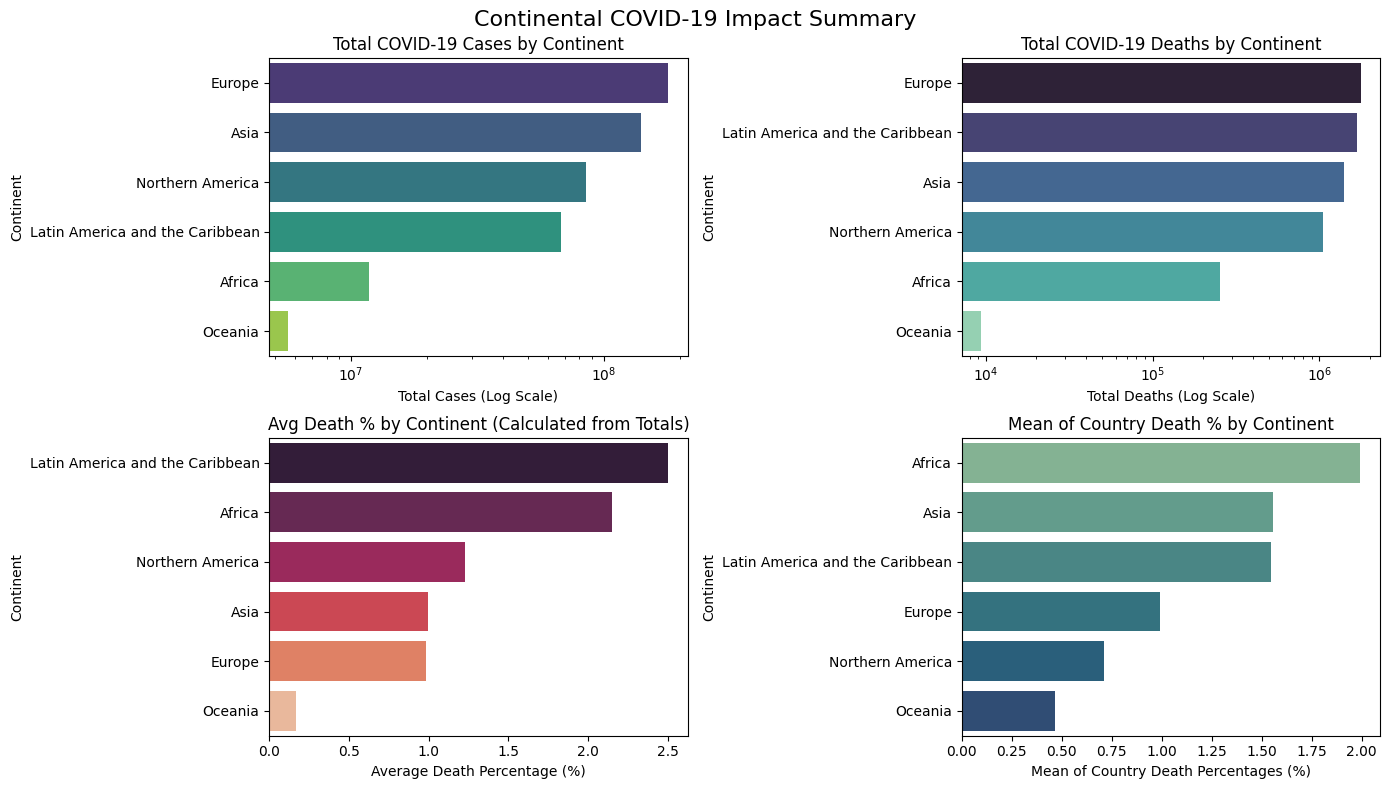

-------------------------


In [235]:
print("\n--- Analysis by Continent ---")

for col in ['Population', 'Total_Cases', 'Total_Deaths', 'Cases_per_1M_pop', 'Deaths_per_1M_pop']:
    if col in df.columns and not pd.api.types.is_numeric_dtype(df[col]):
        df[col] = pd.to_numeric(df[col], errors='coerce')

continent_summary = df.groupby('Continent').agg(
    Total_Population=('Population', 'sum'),
    Total_Cases=('Total_Cases', 'sum'),
    Total_Deaths=('Total_Deaths', 'sum'),
    Avg_Cases_per_1M_pop=('Cases_per_1M_pop', 'mean'),
    Avg_Deaths_per_1M_pop=('Deaths_per_1M_pop', 'mean'),
    Number_of_Countries=('Country', 'count')
).reset_index()

if 'Total_Cases' in continent_summary.columns and 'Total_Deaths' in continent_summary.columns:
    continent_summary['Avg_Death_Percentage_from_Totals'] = (continent_summary['Total_Deaths'] / continent_summary['Total_Cases']) * 100
    continent_summary['Avg_Death_Percentage_from_Totals'] = continent_summary['Avg_Death_Percentage_from_Totals'].fillna(0)
else:
    continent_summary['Avg_Death_Percentage_from_Totals'] = 0

continent_mean_death_percentage = df.groupby('Continent')['Death_percentage'].mean().reset_index()
continent_mean_death_percentage = continent_mean_death_percentage.rename(columns={'Death_percentage': 'Mean_of_Country_Death_Percentages'})
continent_summary = pd.merge(continent_summary, continent_mean_death_percentage, on='Continent', how='left')

print(continent_summary.sort_values(by='Total_Cases', ascending=False))
print("\nObservations from Continental Analysis:")
print("- Europe had the highest number of total cases and total deaths.")
print("- Asia had the largest population but second-highest total cases.")
print("- Latin America and the Caribbean and Africa showed higher average death percentages.")
print("- Oceania had the lowest absolute numbers and death percentage.")

plt.figure(figsize=(14, 8))
plt.subplot(2, 2, 1)
sns.barplot(x='Total_Cases', y='Continent', data=continent_summary.sort_values('Total_Cases', ascending=False), palette="viridis")
plt.title('Total COVID-19 Cases by Continent')
plt.xlabel('Total Cases (Log Scale)')
plt.xscale('log')
plt.tight_layout()

plt.subplot(2, 2, 2)
sns.barplot(x='Total_Deaths', y='Continent', data=continent_summary.sort_values('Total_Deaths', ascending=False), palette="mako")
plt.title('Total COVID-19 Deaths by Continent')
plt.xlabel('Total Deaths (Log Scale)')
plt.xscale('log')
plt.tight_layout()

plt.subplot(2, 2, 3)
sns.barplot(x='Avg_Death_Percentage_from_Totals', y='Continent', data=continent_summary.sort_values('Avg_Death_Percentage_from_Totals', ascending=False), palette="rocket")
plt.title('Avg Death % by Continent (Calculated from Totals)')
plt.xlabel('Average Death Percentage (%)')
plt.tight_layout()

plt.subplot(2, 2, 4)
sns.barplot(x='Mean_of_Country_Death_Percentages', y='Continent', data=continent_summary.sort_values('Mean_of_Country_Death_Percentages', ascending=False), palette="crest")
plt.title('Mean of Country Death % by Continent')
plt.xlabel('Mean of Country Death Percentages (%)')
plt.tight_layout()

plt.suptitle("Continental COVID-19 Impact Summary", fontsize=16)
plt.subplots_adjust(top=0.92)
plt.show()
print("-" * 25)


--- Correlation Analysis ---

Correlation Matrix:
                   Population  Total_Cases  Total_Deaths  Cases_per_1M_pop  \
Population           1.000000     0.430687      0.428189         -0.130130   
Total_Cases          0.430687     1.000000      0.915263          0.127890   
Total_Deaths         0.428189     0.915263      1.000000          0.036561   
Cases_per_1M_pop    -0.130130     0.127890      0.036561          1.000000   
Deaths_per_1M_pop   -0.066485     0.216272      0.289201          0.508630   
Death_percentage     0.083387    -0.032520      0.082616         -0.349986   

                   Deaths_per_1M_pop  Death_percentage  
Population                 -0.066485          0.083387  
Total_Cases                 0.216272         -0.032520  
Total_Deaths                0.289201          0.082616  
Cases_per_1M_pop            0.508630         -0.349986  
Deaths_per_1M_pop           1.000000          0.061088  
Death_percentage            0.061088          1.000000  


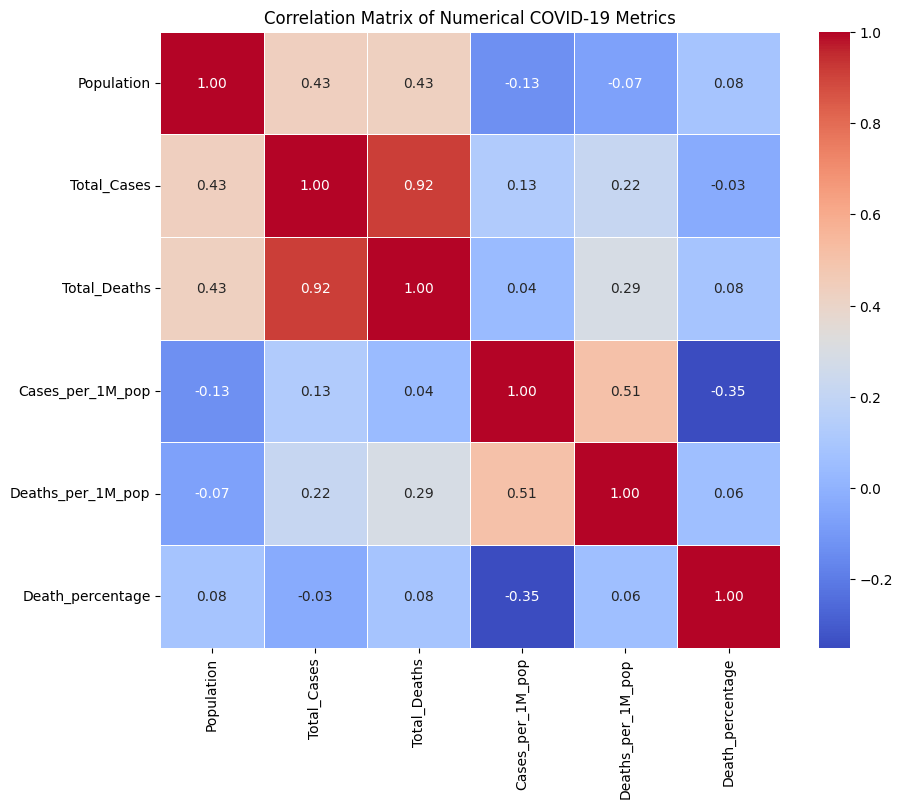


Correlation of Population with Total_Cases: 0.4306868580526075
Correlation of Population with Total_Deaths: 0.428188844095215
Correlation of Cases_per_1M_pop with Deaths_per_1M_pop: 0.5086296661181628


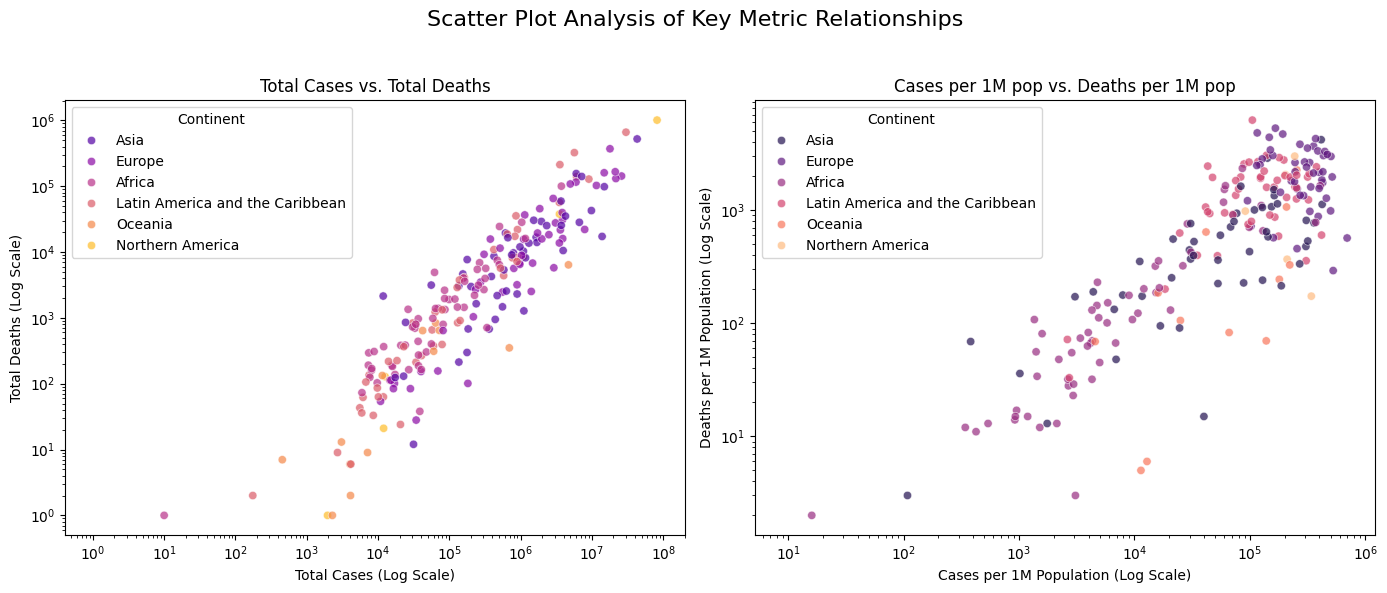

-------------------------


In [236]:
print("\n--- Correlation Analysis ---")

valid_numerical_cols = [col for col in numerical_cols_cleaned if col in df.columns and pd.api.types.is_numeric_dtype(df[col])]
if len(valid_numerical_cols) < len(numerical_cols_cleaned):
    print(f"Warning: Not all expected numerical_cols_cleaned are in df.columns. Using: {valid_numerical_cols}")

if not valid_numerical_cols:
    print("No valid numerical columns found for correlation analysis.")
else:
    correlation_matrix = df[valid_numerical_cols].corr()
    print("\nCorrelation Matrix:")
    print(correlation_matrix)

    plt.figure(figsize=(10, 8))
    sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
    plt.title('Correlation Matrix of Numerical COVID-19 Metrics')
    plt.show()

    if all(col in df.columns for col in ['Population', 'Total_Cases', 'Total_Deaths', 'Cases_per_1M_pop', 'Deaths_per_1M_pop']):
        print("\nCorrelation of Population with Total_Cases:", df['Population'].corr(df['Total_Cases']))
        print("Correlation of Population with Total_Deaths:", df['Population'].corr(df['Total_Deaths']))
        print("Correlation of Cases_per_1M_pop with Deaths_per_1M_pop:", df['Cases_per_1M_pop'].corr(df['Deaths_per_1M_pop']))
    else:
        print("Skipping specific correlations as required columns are missing.")

    if all(col in df.columns for col in ['Total_Cases', 'Total_Deaths', 'Cases_per_1M_pop', 'Deaths_per_1M_pop', 'Continent']):
        plt.figure(figsize=(14, 6))
        plt.subplot(1, 2, 1)
        sns.scatterplot(x='Total_Cases', y='Total_Deaths', data=df, hue='Continent', alpha=0.7, palette="plasma")
        plt.title('Total Cases vs. Total Deaths')
        plt.xscale('log')
        plt.yscale('log')
        plt.xlabel('Total Cases (Log Scale)')
        plt.ylabel('Total Deaths (Log Scale)')

        plt.subplot(1, 2, 2)
        sns.scatterplot(x='Cases_per_1M_pop', y='Deaths_per_1M_pop', data=df, hue='Continent', alpha=0.7, palette="magma")
        plt.title('Cases per 1M pop vs. Deaths per 1M pop')
        plt.xscale('log')
        plt.yscale('log')
        plt.xlabel('Cases per 1M Population (Log Scale)')
        plt.ylabel('Deaths per 1M Population (Log Scale)')

        plt.suptitle("Scatter Plot Analysis of Key Metric Relationships", fontsize=16)
        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()
    else:
        print("Skipping scatter plots as required columns are missing.")
print("-" * 25)


--- Distribution of Key Metrics ---


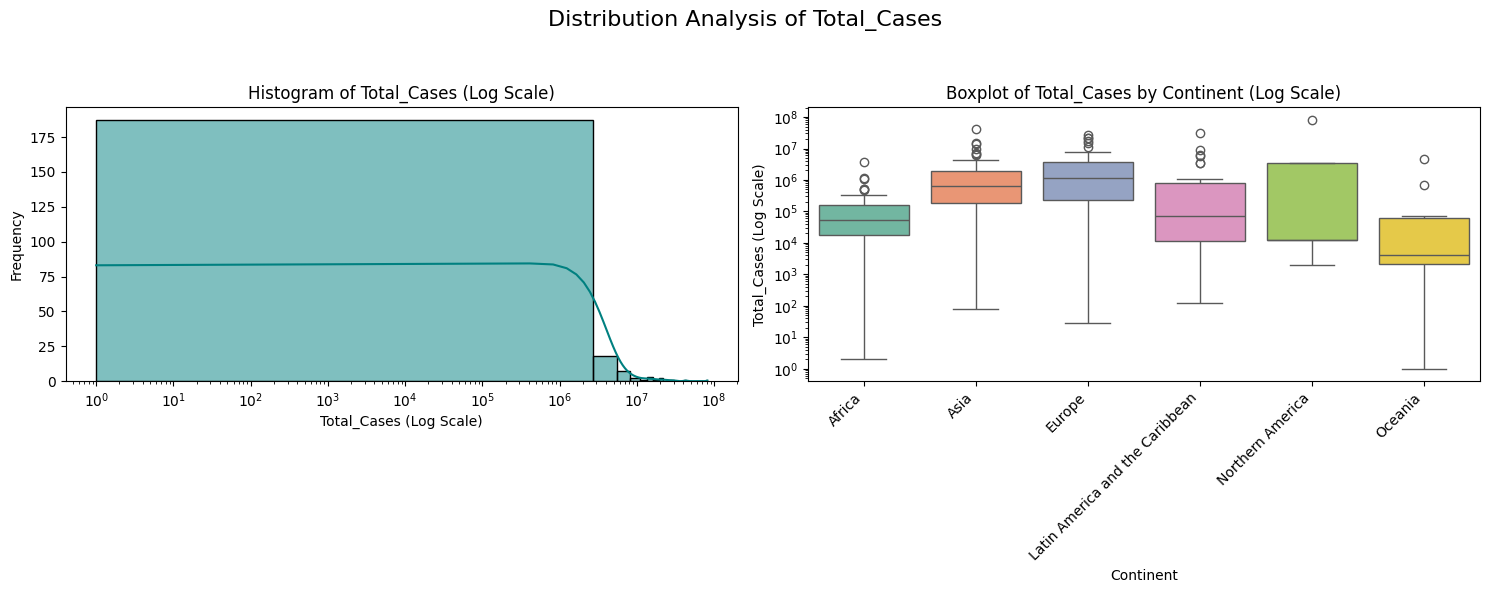

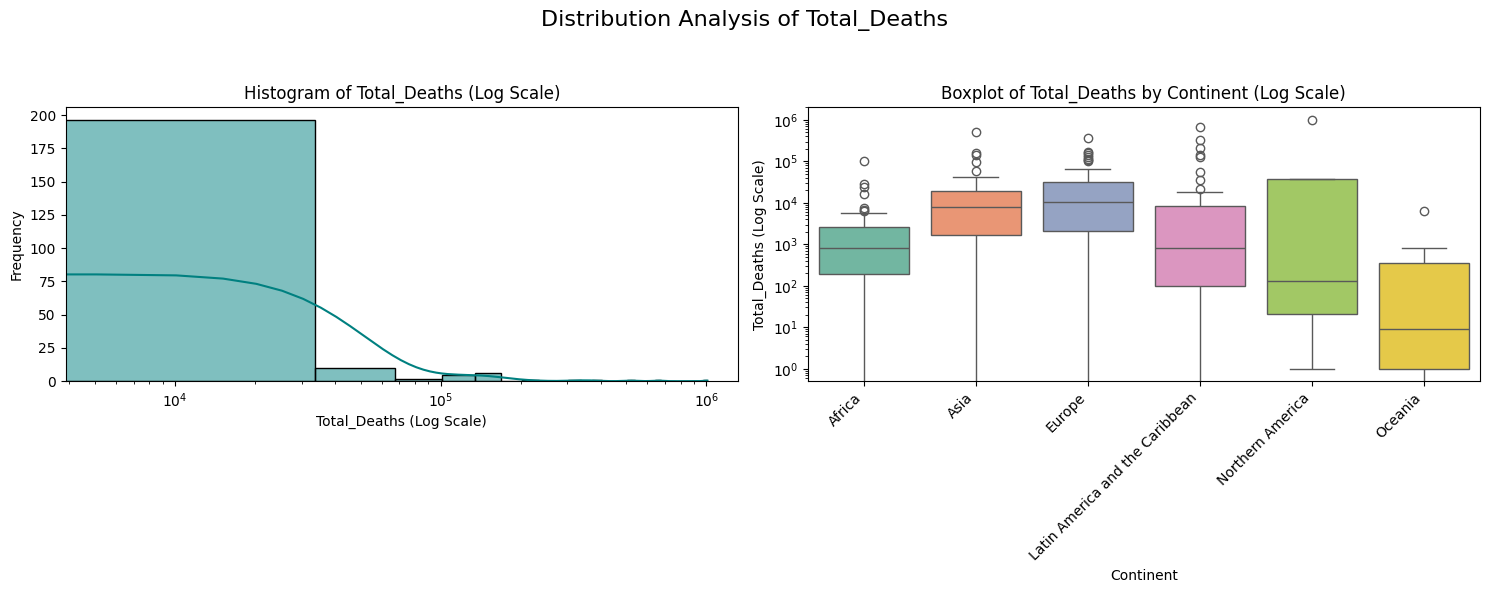

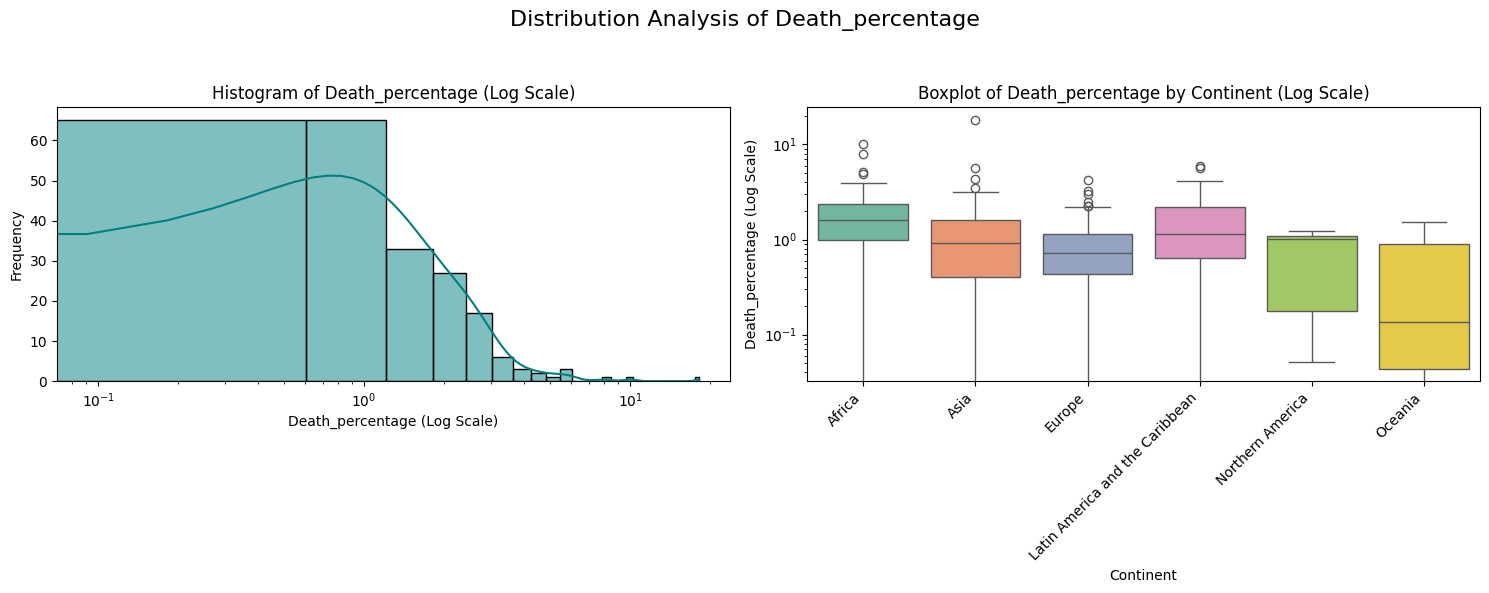

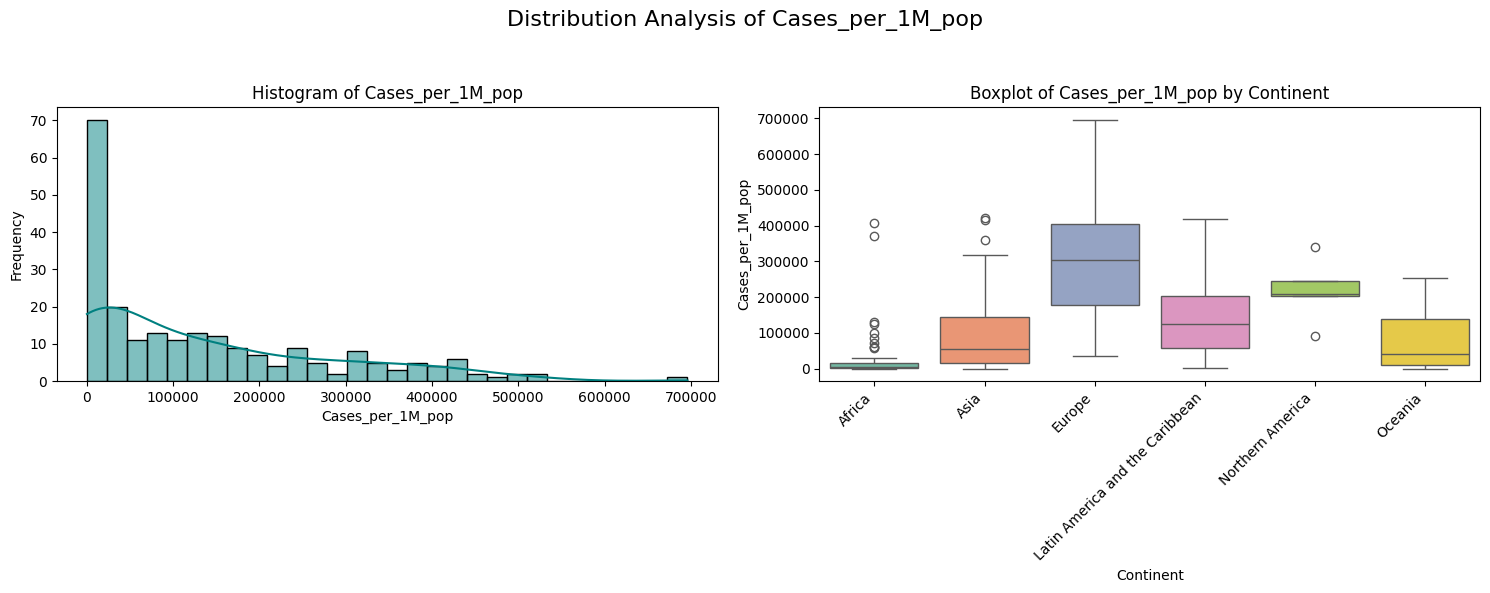

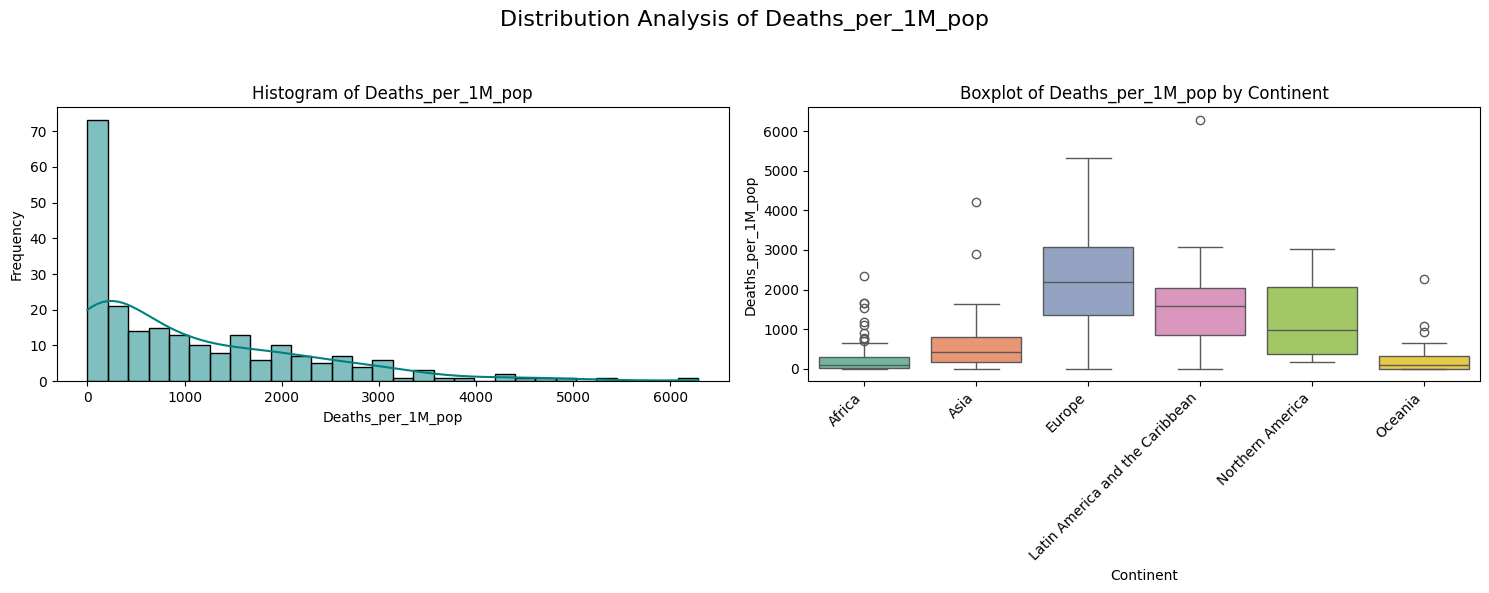

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [237]:
print("\n--- Distribution of Key Metrics ---")
metrics_to_plot_distribution = ['Total_Cases', 'Total_Deaths', 'Death_percentage', 'Cases_per_1M_pop', 'Deaths_per_1M_pop']

for metric in metrics_to_plot_distribution:
    if metric not in df.columns or not pd.api.types.is_numeric_dtype(df[metric]):
        print(f"Skipping distribution for '{metric}' as it's not found or not numeric.")
        continue

    plt.figure(figsize=(15, 6))
    plt.subplot(1, 2, 1)
    sns.histplot(df[metric].dropna(), kde=True, bins=30, color='teal')
    title_hist = f'Histogram of {metric}'
    xlabel_hist = metric
    if df[metric].min() >= 0 and df[metric].max() > 10 * df[metric].median() and df[metric].median() > 0:
        plt.xscale('log')
        title_hist += ' (Log Scale)'
        xlabel_hist += ' (Log Scale)'
    plt.title(title_hist)
    plt.xlabel(xlabel_hist)
    plt.ylabel('Frequency')

    plt.subplot(1, 2, 2)
    if 'Continent' in df.columns:
        sns.boxplot(x='Continent', y=metric, data=df, palette="Set2", order=sorted(df['Continent'].dropna().unique()))
        title_box = f'Boxplot of {metric} by Continent'
        ylabel_box = metric
        if df[metric].min() >= 0 and df[metric].max() > 10 * df[metric].median() and df[metric].median() > 0:
            plt.yscale('log')
            title_box += ' (Log Scale)'
            ylabel_box += ' (Log Scale)'
        plt.title(title_box)
        plt.xlabel('Continent')
        plt.ylabel(ylabel_box)
        plt.xticks(rotation=45, ha='right')
    else:
        plt.text(0.5, 0.5, "'Continent' column not found for boxplot.", ha='center', va='center')
        plt.title(f"Boxplot of {metric} (Continent data missing)")

    plt.suptitle(f'Distribution Analysis of {metric}', fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()
print("-" * 200)

In [238]:
print("\n---Data Transformation (Contextual/Conceptual)---")
print("Scaling is not applied for descriptive EDA. Relevant for specific ML models later.")
print("\nSMOTE: Not relevant for this EDA or regression task.")
print("-" * 100)

print("\n---Feature Engineering and Selection (Contextual)---")
print("Utilized existing and renamed/derived features for this EDA.")
print("No complex feature engineering like RFE applied in this phase.")
print("-" * 100)

print("\n---Analysis of Key Metrics (Focus of EDA)---")
print("EDA above analyzed Total Cases/Deaths, per capita metrics, and Death Percentage.")
print("-" * 100)


---Data Transformation (Contextual/Conceptual)---
Scaling is not applied for descriptive EDA. Relevant for specific ML models later.

SMOTE: Not relevant for this EDA or regression task.
----------------------------------------------------------------------------------------------------

---Feature Engineering and Selection (Contextual)---
Utilized existing and renamed/derived features for this EDA.
No complex feature engineering like RFE applied in this phase.
----------------------------------------------------------------------------------------------------

---Analysis of Key Metrics (Focus of EDA)---
EDA above analyzed Total Cases/Deaths, per capita metrics, and Death Percentage.
----------------------------------------------------------------------------------------------------


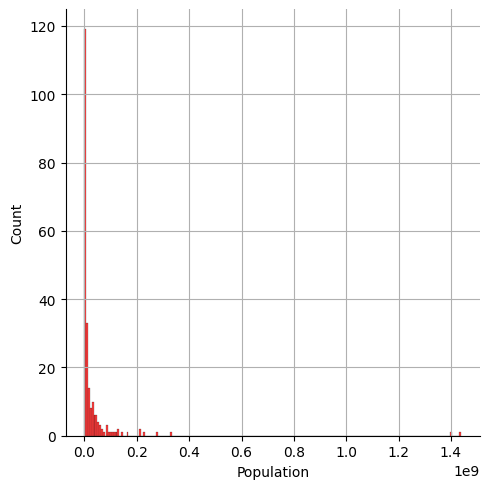

In [239]:
from logging import warning
# to remove warning messages
import warnings
warnings.filterwarnings('ignore')
sns.displot(df['Population'], color='red', edgecolor='black')
plt.grid(True)
plt.show()

In [240]:
print("\n\n--- Exploratory Data Analysis (EDA) ---")



--- Exploratory Data Analysis (EDA) ---


In [241]:
print("\n--- Basic Information ---")
print("Shape of the DataFrame (rows, columns):", df.shape)
print("\nFirst 5 rows:")
print(df.head())
print("\nData types and non-null counts:")
df.info()
print("-" * 100)


--- Basic Information ---
Shape of the DataFrame (rows, columns): (225, 10)

First 5 rows:
       Country Other_names_original ISO_Code  Population Continent  \
0  Afghanistan          Afghanistan      AFG    40462186      Asia   
1      Albania              Albania      ALB     2872296    Europe   
2      Algeria              Algeria      DZA    45236699    Africa   
3      Andorra              Andorra      AND       77481    Europe   
4       Angola               Angola      AGO    34654212    Africa   

   Total_Cases  Total_Deaths  Cases_per_1M_pop  Deaths_per_1M_pop  \
0       177827          7671              4395                190   
1       273870          3492             95349               1216   
2       265691          6874              5873                152   
3        40024           153            516565               1975   
4        99194          1900              2862                 55   

   Death_percentage  
0          4.313743  
1          1.275058  
2     

In [242]:
# Identify numerical and categorical columns
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include='object').columns.tolist()

print("\n--- b. Summary Statistics ---")
print("\nDescriptive statistics for numerical columns:")
print(df[numerical_cols].describe())
print("\nDescriptive statistics for categorical columns:")
print(df[categorical_cols].describe(include='object')) # For object type
for col in categorical_cols:
    print(f"\nValue counts for '{col}':")
    print(df[col].value_counts(dropna=False)) # Include NaNs in counts
    print("-" * 100)


--- b. Summary Statistics ---

Descriptive statistics for numerical columns:
         Population   Total_Cases  Total_Deaths  Cases_per_1M_pop  \
count  2.250000e+02  2.250000e+02  2.250000e+02        225.000000   
mean   3.507321e+07  2.184781e+06  2.744813e+04     136900.373333   
std    1.392418e+08  7.275938e+06  9.689177e+04     145060.340289   
min    8.050000e+02  1.000000e+00  0.000000e+00          9.000000   
25%    5.665570e+05  2.407100e+04  1.890000e+02      11384.000000   
50%    5.827911e+06  1.639360e+05  1.965000e+03      88987.000000   
75%    2.190585e+07  1.092547e+06  1.366000e+04     223335.000000   
max    1.439324e+09  8.183905e+07  1.008222e+06     696044.000000   

       Deaths_per_1M_pop  Death_percentage  
count         225.000000        225.000000  
mean         1096.715556          1.444125  
std          1195.715543          1.741728  
min             0.000000          0.000000  
25%           123.000000          0.511291  
50%           708.000000      

In [243]:
print("\n--- Missing Values ---")
missing_values = df.isnull().sum()
print("Missing values per column:")
print(missing_values[missing_values > 0])
print("-" * 100)


--- Missing Values ---
Missing values per column:
Other_names_original    1
dtype: int64
----------------------------------------------------------------------------------------------------


In [244]:
print("\n\n--- Data Preprocessing ---")
df_processed = df.copy()



--- Data Preprocessing ---


In [245]:
print("\n--- Handling Missing Values ---")
print("Missing values before handling:")
print(df_processed.isnull().sum()[df_processed.isnull().sum() > 0])
print("-" * 100)


--- Handling Missing Values ---
Missing values before handling:
Other_names_original    1
dtype: int64
----------------------------------------------------------------------------------------------------


In [246]:
df_model_ready = df_processed.copy()

In [247]:
print("\nMissing values after handling:")
print(df_processed.isnull().sum()[df_processed.isnull().sum() > 0])
print("-" * 100)


Missing values after handling:
Other_names_original    1
dtype: int64
----------------------------------------------------------------------------------------------------


In [248]:
print("\n--- Categorical Feature Encoding ('Continent') ---")


--- Categorical Feature Encoding ('Continent') ---


In [249]:
df_label = df_model_ready.copy()
df_onehot = df_model_ready.copy()
df_binary = df_model_ready.copy()

In [250]:
from sklearn.preprocessing import LabelEncoder

print("\n-- Label Encoding --")
label_encoder = LabelEncoder()
df_label['Continent_LabelEncoded'] = label_encoder.fit_transform(df_label['Continent'])
print(df_label[['Continent', 'Continent_LabelEncoded']].head())
print("LabelEncoder classes:", label_encoder.classes_)
print("-" * 100)


-- Label Encoding --
  Continent  Continent_LabelEncoded
0      Asia                       1
1    Europe                       2
2    Africa                       0
3    Europe                       2
4    Africa                       0
LabelEncoder classes: ['Africa' 'Asia' 'Europe' 'Latin America and the Caribbean'
 'Northern America' 'Oceania']
----------------------------------------------------------------------------------------------------


In [251]:
print("\n-- One-Hot Encoding --")
df_onehot = pd.get_dummies(df_onehot, columns=['Continent'], prefix='Continent', dummy_na=False)
print(df_onehot[[col for col in df_onehot.columns if 'Continent_' in col]].head())
print("-" * 100)


-- One-Hot Encoding --
   Continent_Africa  Continent_Asia  Continent_Europe  \
0             False            True             False   
1             False           False              True   
2              True           False             False   
3             False           False              True   
4              True           False             False   

   Continent_Latin America and the Caribbean  Continent_Northern America  \
0                                      False                       False   
1                                      False                       False   
2                                      False                       False   
3                                      False                       False   
4                                      False                       False   

   Continent_Oceania  
0              False  
1              False  
2              False  
3              False  
4              False  
--------------------------------------

In [252]:
%pip install category_encoders

In [253]:
import category_encoders as ce

print("\n-- Binary Encoding --")
# Re-create df_binary as a fresh copy of df_model_ready
# This ensures the 'Continent' column is present
df_binary = df_model_ready.copy()


# Instantiate the encoder only once
binary_encoder = ce.BinaryEncoder(cols=['Continent'], return_df=True)

# Add this line to inspect the columns just before encoding (this will show the original columns)
print("Columns in df_binary before encoding:", df_binary.columns)

# Fit and transform the DataFrame
df_binary = binary_encoder.fit_transform(df_binary)

# Add this line to inspect the columns after encoding (this will show the new binary columns and the absence of 'Continent')
print("Columns in df_binary after encoding:", df_binary.columns)

print(df_binary[[col for col in df_binary.columns if 'Continent_' in col]].head())
print("-" * 100)


-- Binary Encoding --
Columns in df_binary before encoding: Index(['Country', 'Other_names_original', 'ISO_Code', 'Population',
       'Continent', 'Total_Cases', 'Total_Deaths', 'Cases_per_1M_pop',
       'Deaths_per_1M_pop', 'Death_percentage'],
      dtype='object')
Columns in df_binary after encoding: Index(['Country', 'Other_names_original', 'ISO_Code', 'Population',
       'Continent_0', 'Continent_1', 'Continent_2', 'Total_Cases',
       'Total_Deaths', 'Cases_per_1M_pop', 'Deaths_per_1M_pop',
       'Death_percentage'],
      dtype='object')
   Continent_0  Continent_1  Continent_2
0            0            0            1
1            0            1            0
2            0            1            1
3            0            1            0
4            0            1            1
----------------------------------------------------------------------------------------------------


In [254]:
from sklearn.model_selection import train_test_split

print("\n--- Data Splitting ---")

# Define X and y (replace 'Total Cases' with your actual target column)
if 'Total Cases' in df_onehot.columns:
    X = df_onehot.drop('Total Cases', axis=1, errors='ignore')
    y = df_onehot['Total Cases']
    print("Defined X and y using 'Total Cases' as the target.")
else:
    print("Error: 'Total Cases' not found in df_onehot. Please define your target variable (y) and features (X).")
    print("Creating dummy X and y to allow the split to run. Replace this with your actual data.")
    X = df_onehot.drop('Continent_Asia', axis=1, errors='ignore')
    y = df_onehot['Continent_Asia']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)
print("-" * 100)


--- Data Splitting ---
Error: 'Total Cases' not found in df_onehot. Please define your target variable (y) and features (X).
Creating dummy X and y to allow the split to run. Replace this with your actual data.
X_train shape: (180, 14)
X_test shape: (45, 14)
y_train shape: (180,)
y_test shape: (45,)
----------------------------------------------------------------------------------------------------


In [255]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

print("\n--- Data Normalization ---")

data_train = {'Population': [1000, 2000, 1500],
              'Total Cases': [100, 200, 150],
              'Continent_Asia': [1, 0, 0],
              'Continent_Europe': [0, 1, 1]}
X_train = pd.DataFrame(data_train)

data_test = {'Population': [1200, 1800],
             'Total Cases': [110, 190],
             'Continent_Asia': [0, 1],
             'Continent_Europe': [1, 0]}
X_test = pd.DataFrame(data_test)


--- Data Normalization ---


In [256]:
numerical_features_to_scale = ['Population', 'Total Cases']
print(f"Numerical features to scale: {numerical_features_to_scale}")

# Create copies to keep original unscaled versions if needed
X_train_scaled_standard = X_train.copy()
X_test_scaled_standard = X_test.copy()

X_train_scaled_minmax = X_train.copy()
X_test_scaled_minmax = X_test.copy()
print("-" * 100)

Numerical features to scale: ['Population', 'Total Cases']
----------------------------------------------------------------------------------------------------


In [257]:
print("\n--- Applying StandardScaler ---")
scaler_standard = StandardScaler()

# Fit on training data's numerical features and transform both train and test
X_train_scaled_standard[numerical_features_to_scale] = scaler_standard.fit_transform(X_train[numerical_features_to_scale])
X_test_scaled_standard[numerical_features_to_scale] = scaler_standard.transform(X_test[numerical_features_to_scale])

print("X_train (Standard Scaled - numerical features):")
print(X_train_scaled_standard[numerical_features_to_scale].head())
print("-" * 100)


--- Applying StandardScaler ---
X_train (Standard Scaled - numerical features):
   Population  Total Cases
0   -1.224745    -1.224745
1    1.224745     1.224745
2    0.000000     0.000000
----------------------------------------------------------------------------------------------------


In [258]:
print("\n--- Applying MinMaxScaler ---")
scaler_minmax = MinMaxScaler()

# Fit on training data's numerical features and transform both train and test
X_train_scaled_minmax[numerical_features_to_scale] = scaler_minmax.fit_transform(X_train[numerical_features_to_scale])
X_test_scaled_minmax[numerical_features_to_scale] = scaler_minmax.transform(X_test[numerical_features_to_scale])

print("X_train (MinMax Scaled - numerical features):")
print(X_train_scaled_minmax[numerical_features_to_scale].head())
# print("X_test (MinMax Scaled - numerical features):")
# print(X_test_scaled_minmax[numerical_features_to_scale].head())

print("\nNormalization complete.")
print("Scaled DataFrames available: X_train_scaled_standard, X_test_scaled_standard, X_train_scaled_minmax, X_test_scaled_minmax")
print("-" * 100)


--- Applying MinMaxScaler ---
X_train (MinMax Scaled - numerical features):
   Population  Total Cases
0         0.0          0.0
1         1.0          1.0
2         0.5          0.5

Normalization complete.
Scaled DataFrames available: X_train_scaled_standard, X_test_scaled_standard, X_train_scaled_minmax, X_test_scaled_minmax
----------------------------------------------------------------------------------------------------


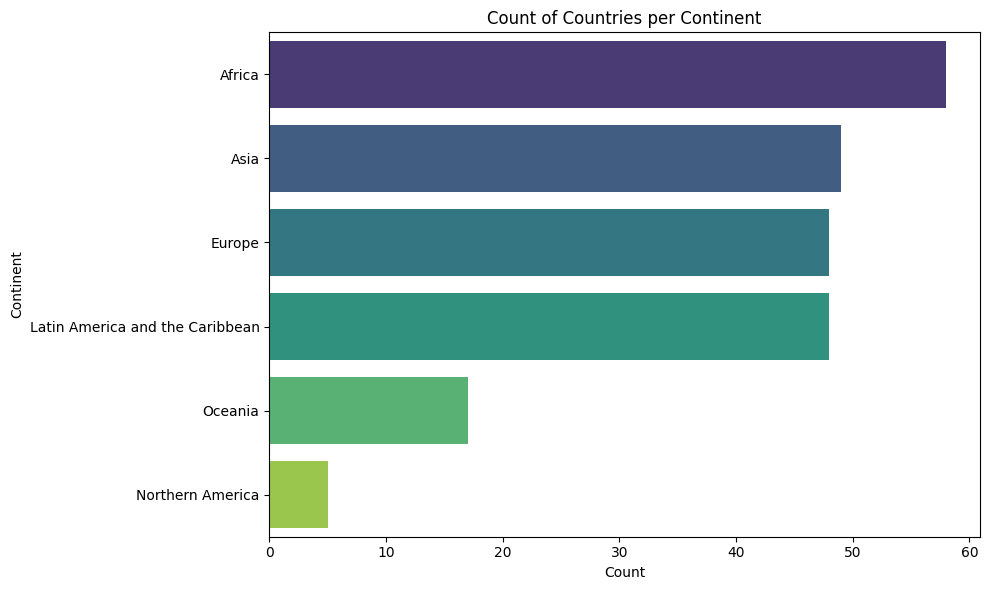

In [259]:
plt.figure(figsize=(10, 6))
sns.countplot(y=df['Continent'], order = df['Continent'].value_counts().index, palette="viridis")
plt.title('Count of Countries per Continent')
plt.xlabel('Count')
plt.ylabel('Continent')
plt.tight_layout()
plt.show()


--- Histograms ---


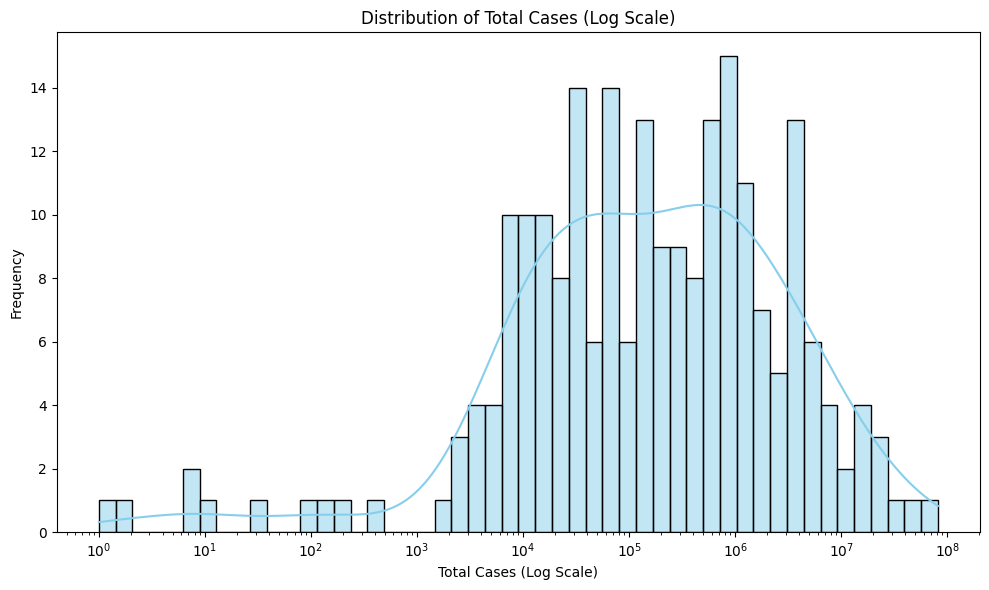

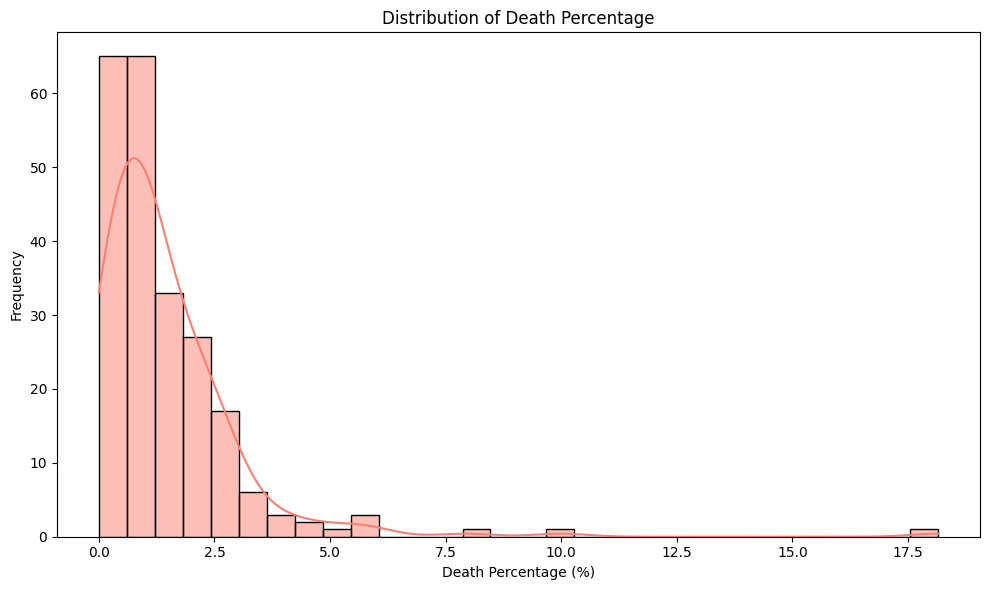

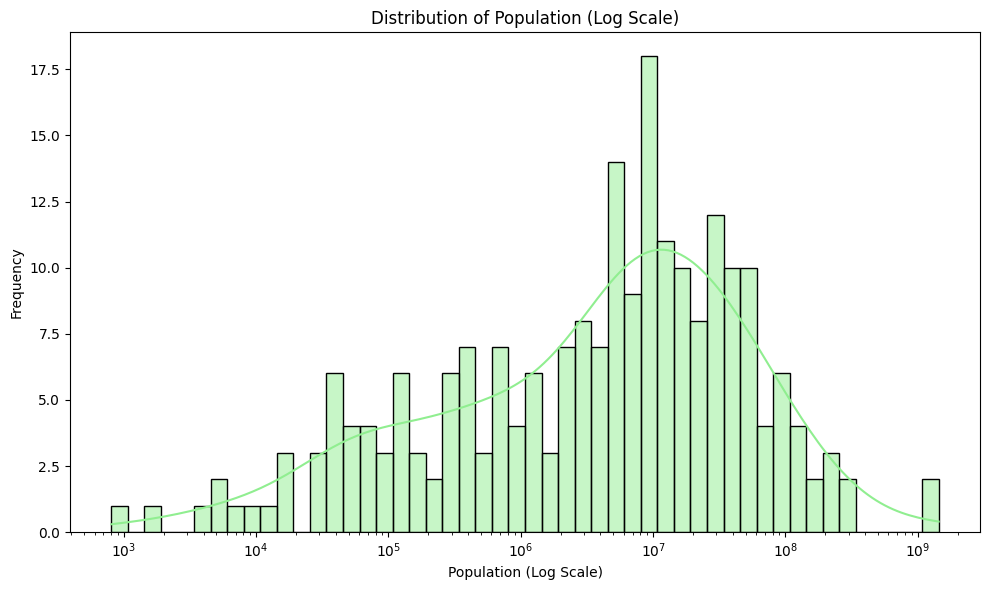

In [260]:
# == A. HISTOGRAMS ==
print("\n--- Histograms ---")

# Histogram for Total Cases (Log Scale due to skewness)
plt.figure(figsize=(10, 6))
sns.histplot(df['Total_Cases'], bins=50, kde=True, log_scale=True, color='skyblue')
plt.title('Distribution of Total Cases (Log Scale)')
plt.xlabel('Total Cases (Log Scale)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# Histogram for Death Percentage
plt.figure(figsize=(10, 6))
sns.histplot(df['Death_percentage'], bins=30, kde=True, color='salmon')
plt.title('Distribution of Death Percentage')
plt.xlabel('Death Percentage (%)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# Histogram for Population (Log Scale)
plt.figure(figsize=(10, 6))
sns.histplot(df['Population'], bins=50, kde=True, log_scale=True, color='lightgreen')
plt.title('Distribution of Population (Log Scale)')
plt.xlabel('Population (Log Scale)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


--- Box Plots ---


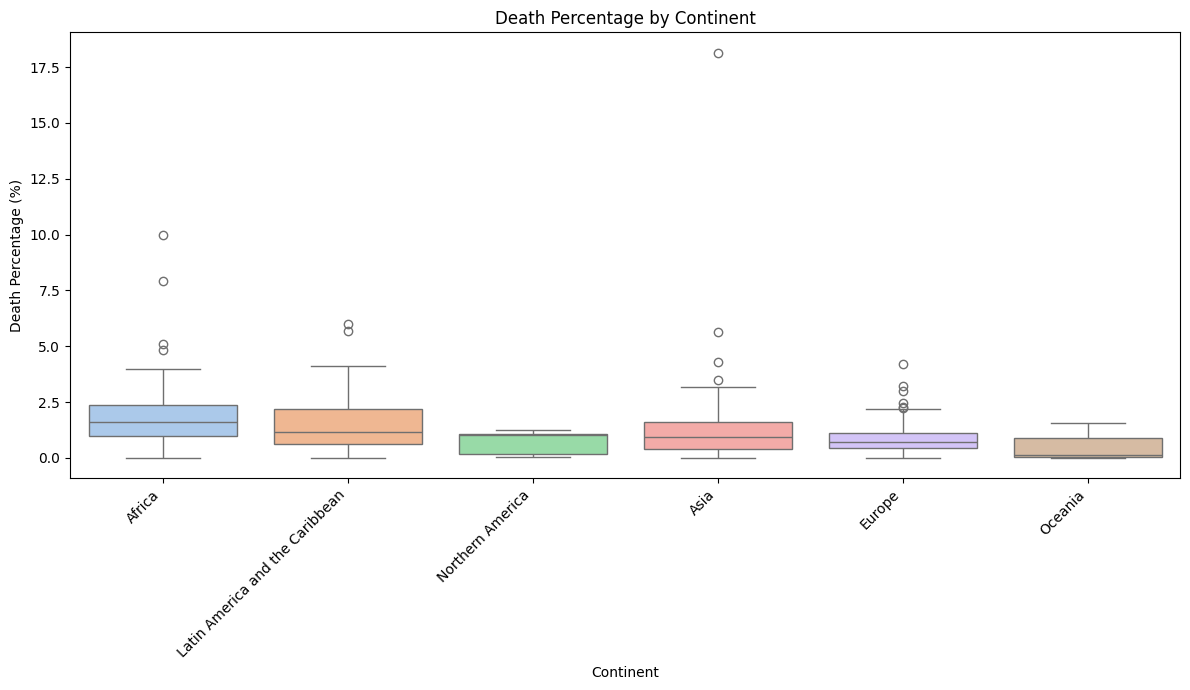

Created 'TotalCasesPer1M' column.


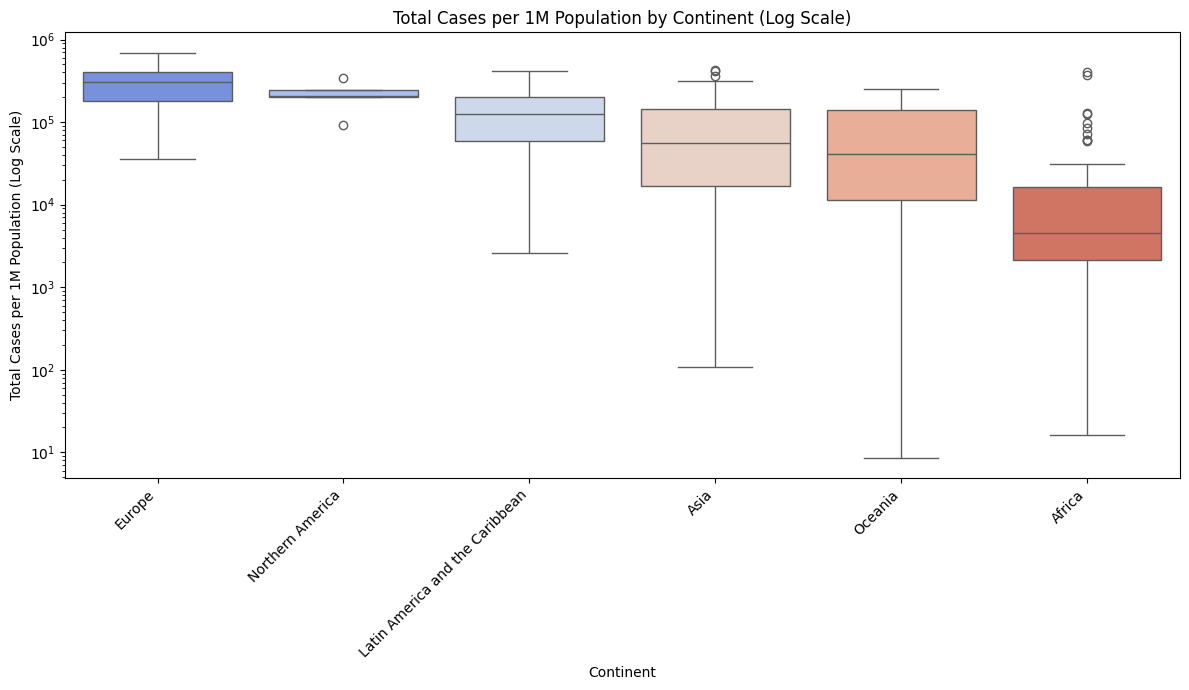

In [261]:
# == B. BOX PLOTS ==
print("\n--- Box Plots ---")

# Box Plot of Death Percentage by Continent
plt.figure(figsize=(12, 7))
# Order continents by median death percentage for better readability
continent_order = df.groupby('Continent')['Death_percentage'].median().sort_values(ascending=False).index
sns.boxplot(x='Continent', y='Death_percentage', data=df, order=continent_order, palette="pastel")
plt.title('Death Percentage by Continent')
plt.xlabel('Continent')
plt.ylabel('Death Percentage (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Calculate 'TotalCasesPer1M' if it doesn't exist
# This step is crucial because the error indicates this column was not found
if 'Total_Cases' in df.columns and 'Population' in df.columns:
    # Ensure Population is not zero to avoid division by zero errors
    df['TotalCasesPer1M'] = (df['Total_Cases'] / df['Population'].replace(0, np.nan)) * 1_000_000
    print("Created 'TotalCasesPer1M' column.")
else:
    print("Warning: Cannot calculate 'TotalCasesPer1M'. 'Total_Cases' or 'Population' column not found.")

# Check again if the column exists before plotting
if 'TotalCasesPer1M' in df.columns:
    # Box Plot of Total Cases per 1M Population by Continent (Log Scale for y-axis)
    plt.figure(figsize=(12, 7))
    # Drop rows where 'TotalCasesPer1M' might be NaN due to zero population
    df_plot = df.dropna(subset=['TotalCasesPer1M']).copy()
    continent_order_cases = df_plot.groupby('Continent')['TotalCasesPer1M'].median().sort_values(ascending=False).index
    sns.boxplot(x='Continent', y='TotalCasesPer1M', data=df_plot, order=continent_order_cases, palette="coolwarm")
    plt.yscale('log') # Use log scale if the spread is very large
    plt.title('Total Cases per 1M Population by Continent (Log Scale)')
    plt.xlabel('Continent')
    plt.ylabel('Total Cases per 1M Population (Log Scale)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("Plotting 'TotalCasesPer1M' skipped as the column could not be created.")


--- Line Plot ---


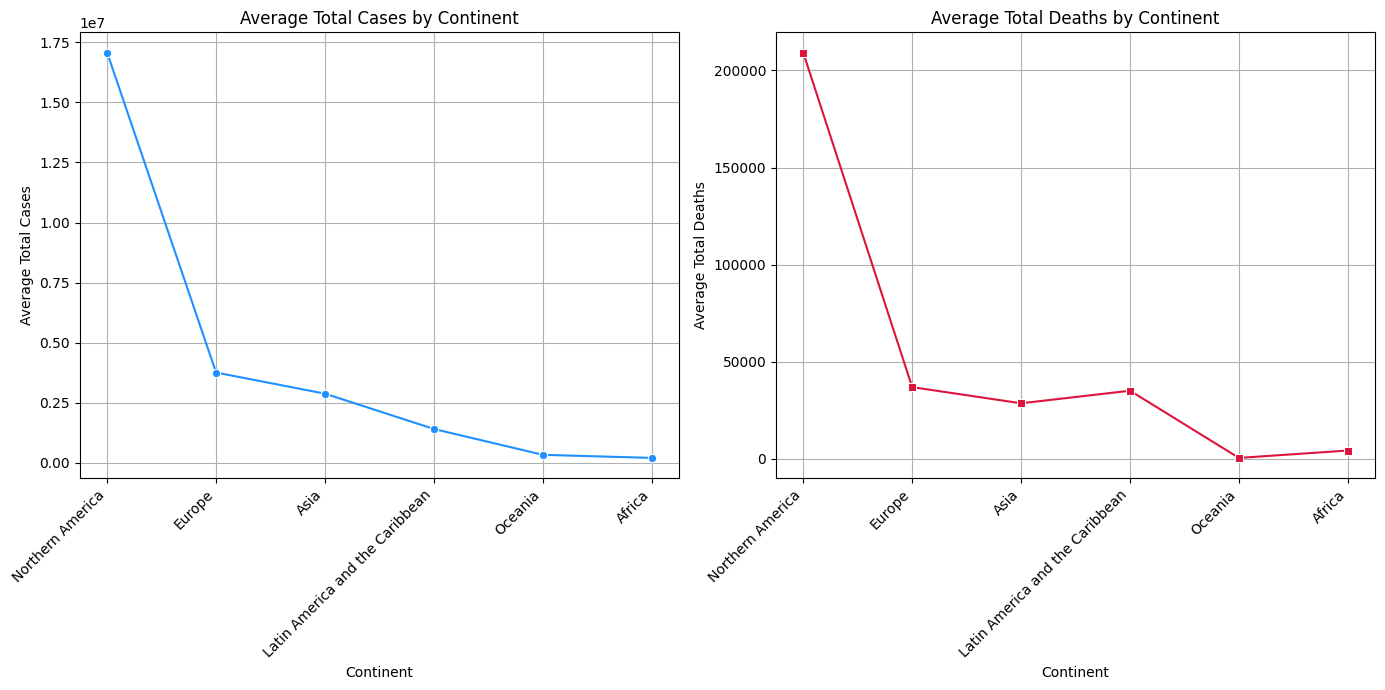

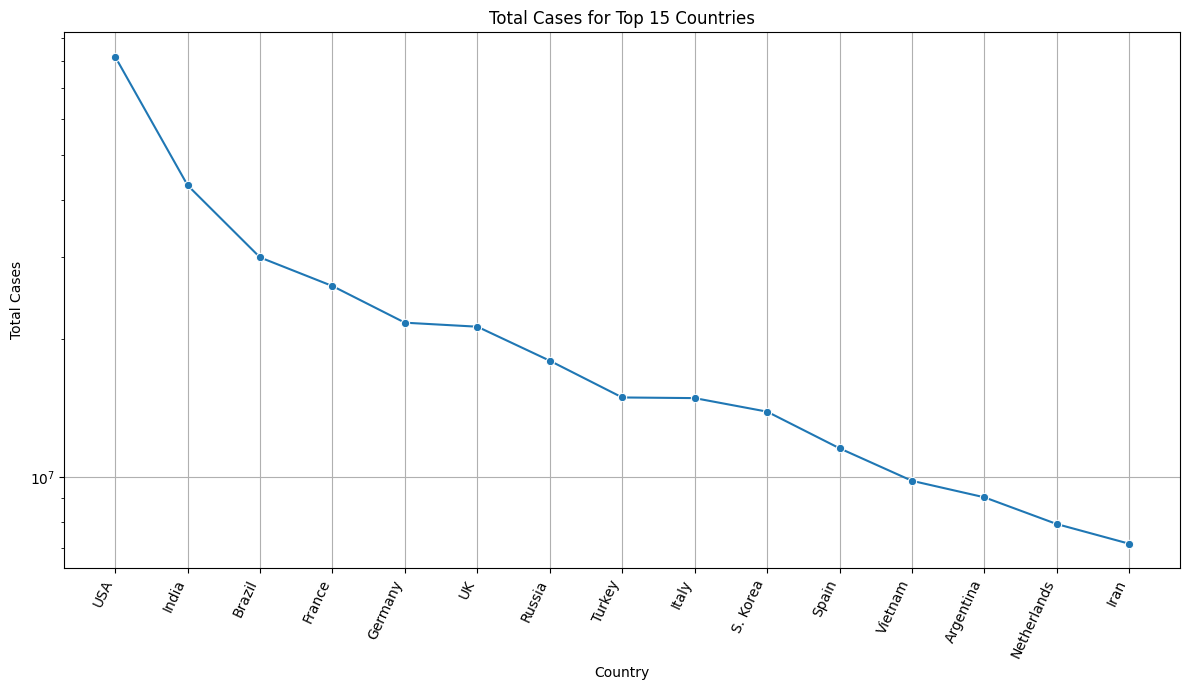

In [262]:
# == C. LINE PLOT ==
print("\n--- Line Plot ---")

continent_summary = df.groupby('Continent')[['Total_Cases', 'Total_Deaths']].mean().reset_index()
# Sorting by one of the metrics can make the trend clearer, or alphabetically
continent_summary = continent_summary.sort_values(by='Total_Cases', ascending=False)

plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
sns.lineplot(x='Continent', y='Total_Cases', data=continent_summary, marker='o', sort=False, color='dodgerblue')
plt.title('Average Total Cases by Continent')
plt.xlabel('Continent')
plt.ylabel('Average Total Cases')
plt.xticks(rotation=45, ha='right')
plt.grid(True)

plt.subplot(1, 2, 2)
sns.lineplot(x='Continent', y='Total_Deaths', data=continent_summary, marker='s', sort=False, color='crimson')
plt.title('Average Total Deaths by Continent')
plt.xlabel('Continent')
plt.ylabel('Average Total Deaths')
plt.xticks(rotation=45, ha='right')
plt.grid(True)

plt.tight_layout()
plt.show()

# Another Line Plot Example: Top N countries by Total Cases
# This isn't a time series, but shows magnitude comparison.
top_n = 15
df_top_cases = df.sort_values(by='Total_Cases', ascending=False).head(top_n)

plt.figure(figsize=(12, 7))
sns.lineplot(x='Country', y='Total_Cases', data=df_top_cases, marker='o', sort=False)
plt.title(f'Total Cases for Top {top_n} Countries')
plt.xlabel('Country')
plt.ylabel('Total Cases')
plt.xticks(rotation=65, ha='right')
plt.yscale('log') # Often necessary for cases
plt.grid(True)
plt.tight_layout()
plt.show()


--- Scatter Plots ---


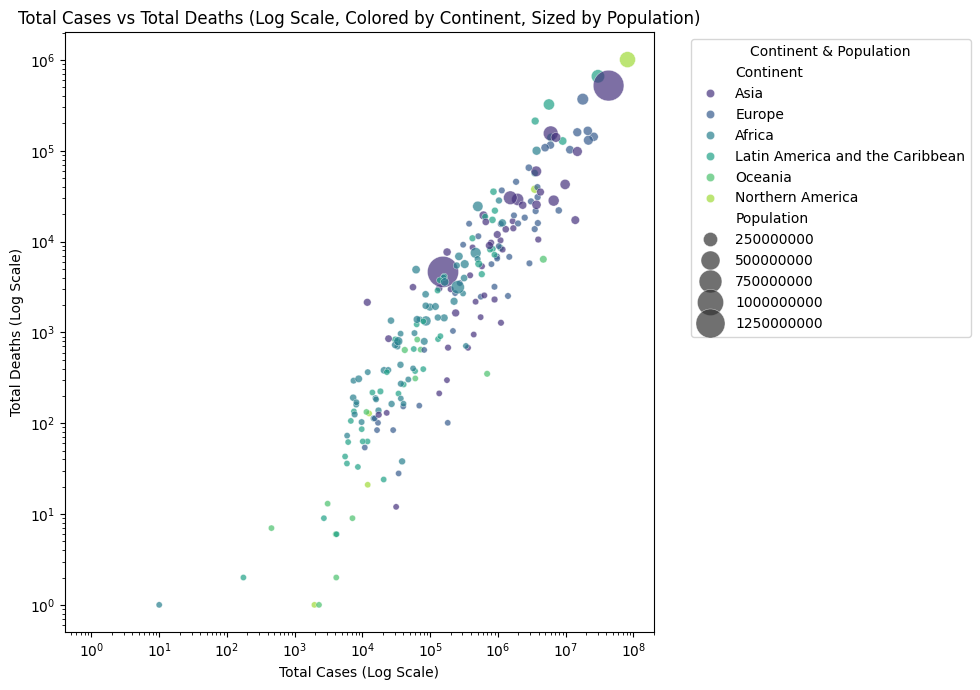

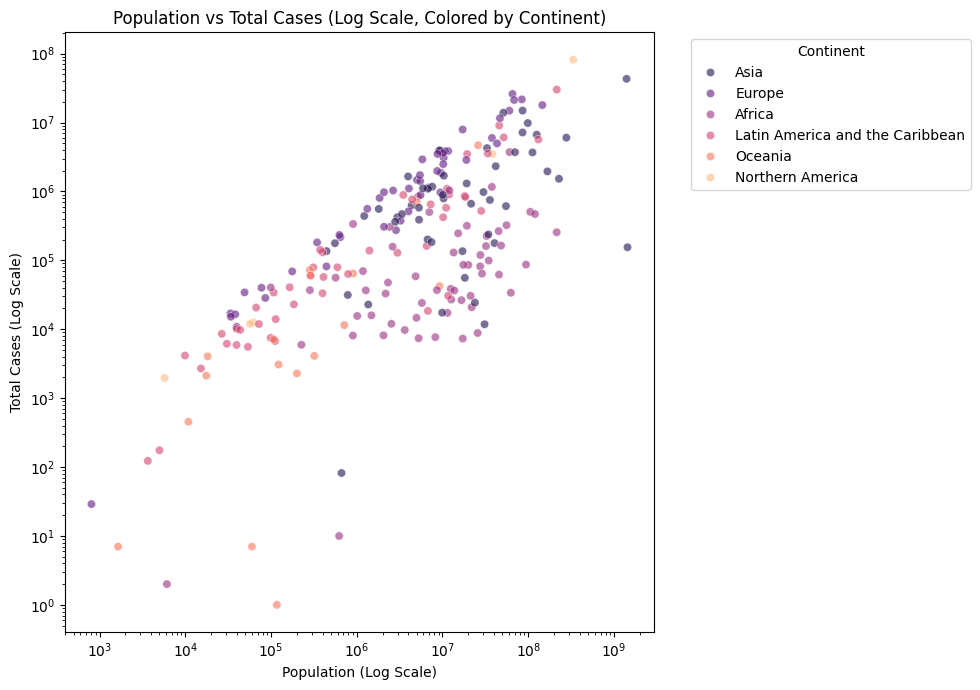

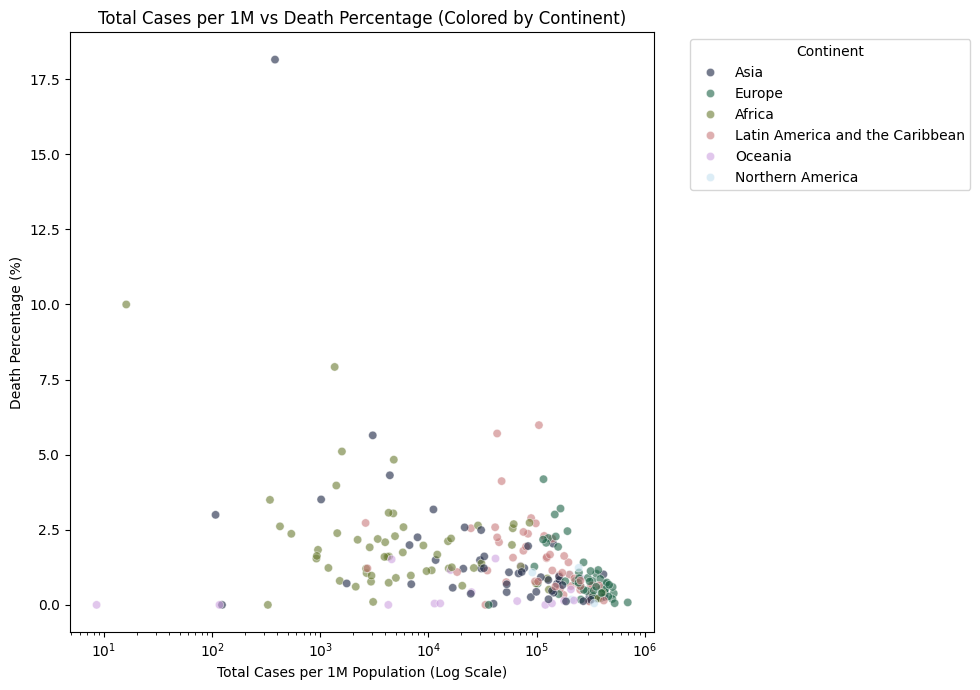


--- Data Visualization Complete ---


In [263]:
# == D. SCATTER PLOTS ==
print("\n--- Scatter Plots ---")

# Scatter Plot: Total Cases vs Total Deaths
plt.figure(figsize=(10, 7))
sns.scatterplot(x='Total_Cases', y='Total_Deaths', hue='Continent', size='Population',
                data=df, alpha=0.7, sizes=(20, 500), palette="viridis")
plt.xscale('log')
plt.yscale('log')
plt.title('Total Cases vs Total Deaths (Log Scale, Colored by Continent, Sized by Population)')
plt.xlabel('Total Cases (Log Scale)')
plt.ylabel('Total Deaths (Log Scale)')
plt.legend(title='Continent & Population', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Scatter Plot: Population vs Total Cases
plt.figure(figsize=(10, 7))
sns.scatterplot(x='Population', y='Total_Cases', hue='Continent',
                data=df, alpha=0.6, palette="magma")
plt.xscale('log')
plt.yscale('log')
plt.title('Population vs Total Cases (Log Scale, Colored by Continent)')
plt.xlabel('Population (Log Scale)')
plt.ylabel('Total Cases (Log Scale)')
plt.legend(title='Continent', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Scatter Plot: TotalCasesPer1M vs Death Percentage
plt.figure(figsize=(10, 7))
sns.scatterplot(x='TotalCasesPer1M', y='Death_percentage', hue='Continent',
                data=df, alpha=0.6, palette="cubehelix")
plt.xscale('log') # TotalCasesPer1M can be skewed
# plt.yscale('log') # Death percentage might not need log scale
plt.title('Total Cases per 1M vs Death Percentage (Colored by Continent)')
plt.xlabel('Total Cases per 1M Population (Log Scale)')
plt.ylabel('Death Percentage (%)')
plt.legend(title='Continent', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

print("\n--- Data Visualization Complete ---")

In [264]:
# Import necessary libraries
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import numpy as np

# --- 1. Regression Task: Predicting 'Total Deaths' ---
print("\n--- Starting Regression Task: Predicting Total Deaths ---")

# Define features (X) and target (y)
# We will use Population, Total Cases, and Continent as features.
# 'tot_cases_per_1m_pop' and 'tot_deaths_per_1m_pop' are directly derived from target or other features and population,
# so using them to predict 'total_deaths' might be too direct or cause multicollinearity.
# 'death_percentage' is also directly calculated from 'total_deaths' and 'total_cases'.
features_reg = ['Population', 'Total_Cases', 'Continent']
target_reg = 'Total_Deaths'

X_reg = df[features_reg]
y_reg = df[target_reg]

# Preprocessing:
# Numerical features: 'Population', 'Total Cases' -> StandardScaler
# Categorical features: 'Continent' -> OneHotEncoder
numerical_features_reg = ['Population', 'Total_Cases']
categorical_features_reg = ['Continent']

preprocessor_reg = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features_reg),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features_reg)
    ])

# Split data into training and testing sets
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

# --- Model 1: Linear Regression ---
pipeline_lr = Pipeline(steps=[('preprocessor', preprocessor_reg),
                              ('regressor', LinearRegression())])
pipeline_lr.fit(X_train_reg, y_train_reg)
y_pred_lr = pipeline_lr.predict(X_test_reg)

# Evaluation for Linear Regression
print("\nLinear Regression - Evaluation:")
mse_lr = mean_squared_error(y_test_reg, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)

print(f"Mean Squared Error (MSE): {mse_lr:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse_lr:.2f}")
print("-" * 100)


--- Starting Regression Task: Predicting Total Deaths ---

Linear Regression - Evaluation:
Mean Squared Error (MSE): 1389301376.27
Root Mean Squared Error (RMSE): 37273.33
----------------------------------------------------------------------------------------------------
